# H4-specific EDA: a closer look at transaction_data

Focusing on the columns actually used in H4/H4-1/H4-2 (household_key, DAY, WEEK_NO, BASKET_ID, SALES_VALUE),
this goes one step deeper than the earlier overview notebook of the 8 tables.

**Purpose**
1. Check shape, types and duplicate rows
2. Check missing values
3. SALES_VALUE distribution (outliers, negative values, and anything else that could affect the H4 computations)
4. Cautions when aggregating by household_key (e.g. differences in the number of observations per household)
5. Re-check after filtering to the stable window (weeks 17-99)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["axes.unicode_minus"] = False  # keep the minus sign as a plain hyphen

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 150)

from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED

tx = pd.read_csv(DATA_DIR / "transaction_data.csv")
print("shape:", tx.shape)
tx.head()

shape: (2595732, 12)


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


## 1. Basic structure

- dtypes, memory usage
- Whether fully duplicated rows exist (if the same transaction was loaded twice, the SALES_VALUE sum would be inflated twofold)
- Pick out only the columns used in H4 for the later work

In [2]:
print("--- dtypes ---")
print(tx.dtypes)

print(f"\nMemory usage: {tx.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

n_dup = tx.duplicated().sum()
print(f"\nFully duplicated rows: {n_dup:,} ({n_dup/len(tx)*100:.3f}%)")
if n_dup > 0:
    print("Warning: duplicated rows exist; decide whether to remove them before the H4 aggregation")

# Key columns used in H4
h4_cols = ["household_key", "BASKET_ID", "DAY", "WEEK_NO", "SALES_VALUE"]
print("\nMissing values in the key columns")
print(tx[h4_cols].isna().sum())


--- dtypes ---
household_key          int64
BASKET_ID              int64
DAY                    int64
PRODUCT_ID             int64
QUANTITY               int64
SALES_VALUE          float64
STORE_ID               int64
RETAIL_DISC          float64
TRANS_TIME             int64
WEEK_NO                int64
COUPON_DISC          float64
COUPON_MATCH_DISC    float64
dtype: object

Memory usage: 237.6 MB



Fully duplicated rows: 0 (0.000%)

Missing values in the key columns
household_key    0
BASKET_ID        0
DAY              0
WEEK_NO          0
SALES_VALUE      0
dtype: int64


## 2. Basic statistics for household_key and BASKET_ID

- Number of unique households and unique baskets
- Distribution of rows per household: whether some households have extremely few or many (a distortion factor when computing the H4 ranking)

Unique household_key: 2,500
Unique BASKET_ID: 276,484
WEEK_NO range: 1 to 102
DAY range: 1 to 711

Distribution of transaction rows per household
count    2500.000000
mean     1038.292800
std       999.097354
min         4.000000
25%       325.000000
50%       734.000000
75%      1454.500000
max      6851.000000
dtype: float64


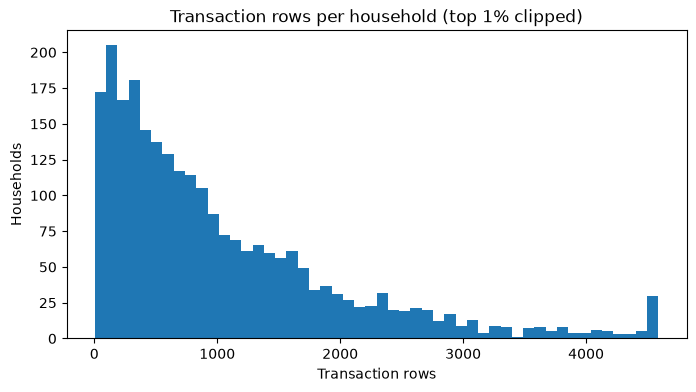


Households in the bottom 1% by transaction rows (extremely little activity): 25


In [3]:
print(f"Unique household_key: {tx['household_key'].nunique():,}")
print(f"Unique BASKET_ID: {tx['BASKET_ID'].nunique():,}")
print(f"WEEK_NO range: {tx['WEEK_NO'].min()} to {tx['WEEK_NO'].max()}")
print(f"DAY range: {tx['DAY'].min()} to {tx['DAY'].max()}")

rows_per_hh = tx.groupby("household_key").size()
print("\nDistribution of transaction rows per household")
print(rows_per_hh.describe())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(rows_per_hh.clip(upper=rows_per_hh.quantile(0.99)), bins=50)
ax.set_title("Transaction rows per household (top 1% clipped)")
ax.set_xlabel("Transaction rows")
ax.set_ylabel("Households")
plt.show()

print(f"\nHouseholds in the bottom 1% by transaction rows (extremely little activity): {(rows_per_hh <= rows_per_hh.quantile(0.01)).sum()}")


## 3. SALES_VALUE distribution and outliers

This is the key column of the H4 computations, so it deserves the closest look.
- Share of negative values (presumed refunds)
- Share of zero values
- Whether extreme values (upper outliers) exist, by the IQR rule

SALES_VALUE summary statistics
count    2.595732e+06
mean     3.104120e+00
std      4.182274e+00
min      0.000000e+00
25%      1.290000e+00
50%      2.000000e+00
75%      3.490000e+00
max      8.400000e+02
Name: SALES_VALUE, dtype: float64

Negative SALES_VALUE rows: 0 (0.000%)
Zero SALES_VALUE rows: 18,850 (0.726%)

Upper outliers by the IQR rule (> 6.79): 190,644 rows (7.34%)
Maximum: 840.00


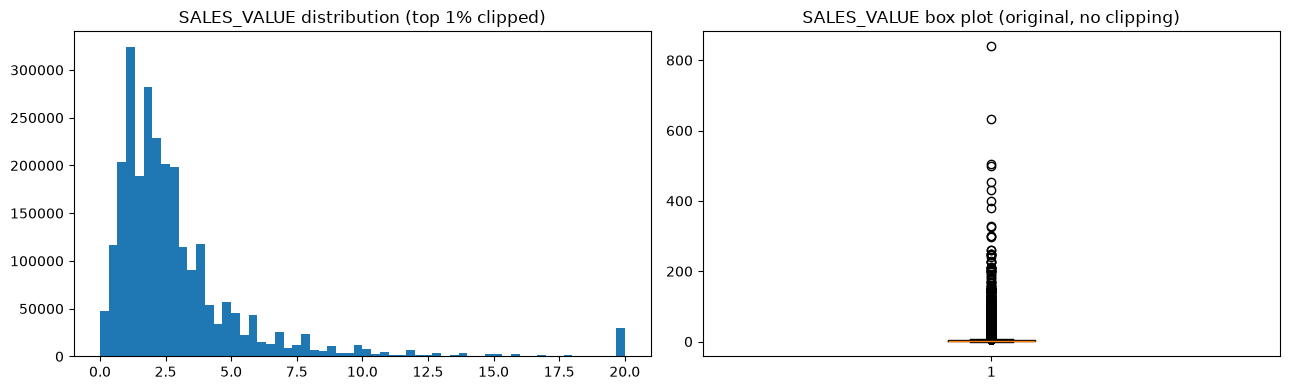

In [4]:
print("SALES_VALUE summary statistics")
print(tx["SALES_VALUE"].describe())

n_negative = (tx["SALES_VALUE"] < 0).sum()
n_zero = (tx["SALES_VALUE"] == 0).sum()
print(f"\nNegative SALES_VALUE rows: {n_negative:,} ({n_negative/len(tx)*100:.3f}%)")
print(f"Zero SALES_VALUE rows: {n_zero:,} ({n_zero/len(tx)*100:.3f}%)")

# Outliers by the IQR rule
q1, q3 = tx["SALES_VALUE"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
n_outlier = (tx["SALES_VALUE"] > upper_bound).sum()
print(f"\nUpper outliers by the IQR rule (> {upper_bound:.2f}): {n_outlier:,} rows ({n_outlier/len(tx)*100:.2f}%)")
print(f"Maximum: {tx['SALES_VALUE'].max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(tx["SALES_VALUE"].clip(upper=tx["SALES_VALUE"].quantile(0.99)), bins=60)
axes[0].set_title("SALES_VALUE distribution (top 1% clipped)")
axes[1].boxplot(tx["SALES_VALUE"], orientation="vertical")
axes[1].set_title("SALES_VALUE box plot (original, no clipping)")
plt.tight_layout()
plt.show()


In [5]:
# --- source CSV: SALES_VALUE summary (README: IQR outlier share)
pd.DataFrame([{
    "n_rows": len(tx), "n_zero": int(n_zero), "n_negative": int(n_negative),
    "iqr_upper_bound": upper_bound, "n_iqr_outliers": int(n_outlier),
    "pct_iqr_outliers": n_outlier / len(tx) * 100, "max_sales_value": tx["SALES_VALUE"].max(),
}]).to_csv(OUT_DIR / "h4_sales_value_summary.csv", index=False)

In [6]:
# If negative values exist, look at what they actually look like
if n_negative > 0:
    print("Sample of negative SALES_VALUE rows")
    display(tx[tx["SALES_VALUE"] < 0].head(10))


## 4. Distribution of total SALES_VALUE per household (whole period)

H4 ultimately deals with the "ranking of total spending per household", so look at the aggregated distribution in advance too.
Check that a few extreme households (bulk purchases / abnormal transactions) do not distort the ranking.

Total SALES_VALUE per household (whole period): summary
count     2500.000000
mean      3222.985232
std       3349.026076
min          8.170000
25%        970.740000
50%       2157.750000
75%       4413.320000
max      38319.790000
Name: SALES_VALUE, dtype: float64


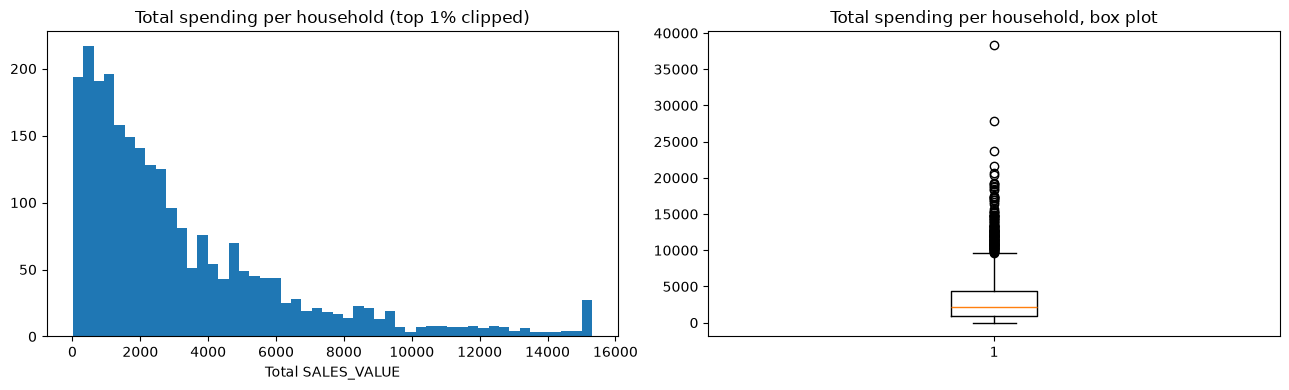


Top 5 households by total spending
household_key
1023    38319.79
1609    27859.68
2322    23646.92
1453    21661.29
2459    20671.50
Name: SALES_VALUE, dtype: float64

Bottom 5 households by total spending (very little activity)
household_key
522     29.34
689     28.96
2201    27.51
1897    19.58
494      8.17
Name: SALES_VALUE, dtype: float64


In [7]:
hh_total_sales = tx.groupby("household_key")["SALES_VALUE"].sum().sort_values(ascending=False, kind="stable")

print("Total SALES_VALUE per household (whole period): summary")
print(hh_total_sales.describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(hh_total_sales.clip(upper=hh_total_sales.quantile(0.99)), bins=50)
axes[0].set_title("Total spending per household (top 1% clipped)")
axes[0].set_xlabel("Total SALES_VALUE")

axes[1].boxplot(hh_total_sales, orientation="vertical")
axes[1].set_title("Total spending per household, box plot")
plt.tight_layout()
plt.show()

print("\nTop 5 households by total spending")
print(hh_total_sales.head())
print("\nBottom 5 households by total spending (very little activity)")
print(hh_total_sales.tail())


## 5. Re-check after filtering to the stable window (WEEK_NO 17-99)

As decided last time, exclude the onboarding (weeks 1-16) and truncated (weeks 100-102) windows,
repeat the same checks, and look at the difference before and after filtering.

In [8]:
tx_stable = tx[(tx["WEEK_NO"] >= 17) & (tx["WEEK_NO"] <= 99)].copy()

print(f"Before filtering: {len(tx):,} rows, {tx['household_key'].nunique():,} households")
print(f"After filtering (stable window): {len(tx_stable):,} rows, {tx_stable['household_key'].nunique():,} households")
print(f"Share of rows excluded: {(1 - len(tx_stable)/len(tx))*100:.1f}%")

hh_total_sales_stable = tx_stable.groupby("household_key")["SALES_VALUE"].sum().sort_values(ascending=False, kind="stable")
print("\nTotal spending per household, stable window: summary")
print(hh_total_sales_stable.describe())


Before filtering: 2,595,732 rows, 2,500 households
After filtering (stable window): 2,317,271 rows, 2,492 households
Share of rows excluded: 10.7%

Total spending per household, stable window: summary
count     2492.000000
mean      2892.329165
std       3077.855256
min          4.490000
25%        820.977500
50%       1905.725000
75%       3989.860000
max      36836.490000
Name: SALES_VALUE, dtype: float64


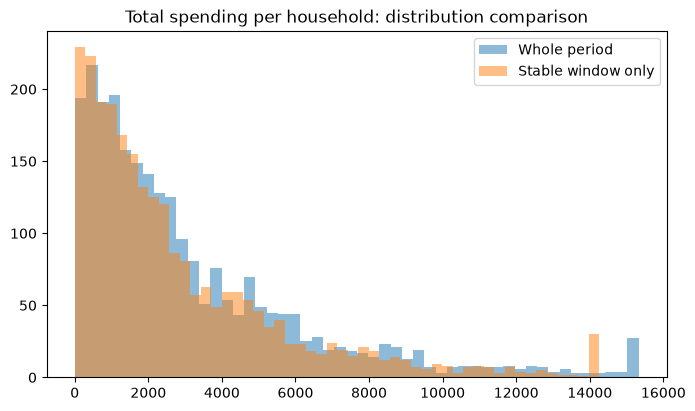


Households present in the whole period but with no transactions in the stable window: 8


In [9]:
# Compare total spending per household: whole period vs stable window
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(hh_total_sales.clip(upper=hh_total_sales.quantile(0.99)), bins=50, alpha=0.5, label="Whole period")
ax.hist(hh_total_sales_stable.clip(upper=hh_total_sales_stable.quantile(0.99)), bins=50, alpha=0.5, label="Stable window only")
ax.set_title("Total spending per household: distribution comparison")
ax.legend()
plt.show()

# Whether some households are absent from the stable window (i.e. exist only in the onboarding/truncated windows)
hh_all = set(tx["household_key"].unique())
hh_stable = set(tx_stable["household_key"].unique())
print(f"\nHouseholds present in the whole period but with no transactions in the stable window: {len(hh_all - hh_stable):,}")


In [10]:
# --- source CSV: household / row counts before and after the stable-window filter
pd.DataFrame([
    {"metric": "households_all", "value": len(hh_all)},
    {"metric": "households_stable_17_99", "value": len(hh_stable)},
    {"metric": "households_only_outside_stable", "value": len(hh_all - hh_stable)},
    {"metric": "rows_all", "value": len(tx)},
    {"metric": "rows_stable_17_99", "value": len(tx_stable)},
    {"metric": "pct_rows_excluded", "value": (1 - len(tx_stable) / len(tx)) * 100},
]).to_csv(OUT_DIR / "h4_household_counts.csv", index=False)

## 6. Notes for the next step

- Settle here the policy for negative/outlier SALES_VALUE (remove vs keep as is) and apply it consistently in the H4 computations
- When deciding the length of the early window (N weeks) later, work from this notebook's `tx_stable` (the data filtered to the stable window)
- If the number of observations per household varies widely, an early window that is too short may leave some households with no observations at all; see the variation found in section 3

Compute how many early weeks to use. The purpose is to pick the top-spending households; if later-period data were included, we would fall into a contradiction: did the number of households that were originally on top grow, or did we define the grown households as the top?
The convention is 20%, but explore the curvature with kneed.

In [11]:
from scipy.stats import spearmanr

# Check the stable-window range (team agreement: from week 17, upper end kept at the existing week 99)
stable_min_week = tx_stable["WEEK_NO"].min()
stable_max_week = tx_stable["WEEK_NO"].max()
total_stable_weeks = stable_max_week - stable_min_week + 1
print(f"Stable window: weeks {stable_min_week} to {stable_max_week} ({total_stable_weeks} weeks in total)")

candidate_N = [2, 4, 6, 8, 10, 12, 16, 20]
results = []

for N in candidate_N:
    window = tx_stable[
        (tx_stable["WEEK_NO"] >= stable_min_week) &
        (tx_stable["WEEK_NO"] < stable_min_week + N)
    ].copy()

    # Split into odd/even weeks within the window (by relative order within the window, not by absolute WEEK_NO)
    window["week_rel"] = window["WEEK_NO"] - stable_min_week
    odd_weeks  = window[window["week_rel"] % 2 == 1]
    even_weeks = window[window["week_rel"] % 2 == 0]

    sales_odd  = odd_weeks.groupby("household_key")["SALES_VALUE"].sum()
    sales_even = even_weeks.groupby("household_key")["SALES_VALUE"].sum()

    # Compare only households present in both halves (no rank comparison if present in only one)
    common_hh = sales_odd.index.intersection(sales_even.index)

    if len(common_hh) < 10:
        results.append({"N": N, "n_households": len(common_hh), "spearman_rho": np.nan})
        continue

    rho, pval = spearmanr(sales_odd.loc[common_hh], sales_even.loc[common_hh])
    results.append({
        "N": N,
        "n_households": len(common_hh),
        "spearman_rho": rho,
        "pct_of_stable_range": round(N / total_stable_weeks * 100, 1),
    })

rank_stability = pd.DataFrame(results)
rank_stability

Stable window: weeks 17 to 99 (83 weeks in total)


,N,n_households,spearman_rho,pct_of_stable_range
0,2,947,0.404566,2.4
1,4,1397,0.487859,4.8
2,6,1663,0.574319,7.2
3,8,1812,0.640430,9.6
4,10,1913,0.697030,12.0
5,12,1986,0.728662,14.5
6,16,2110,0.780408,19.3
7,20,2188,0.815526,24.1


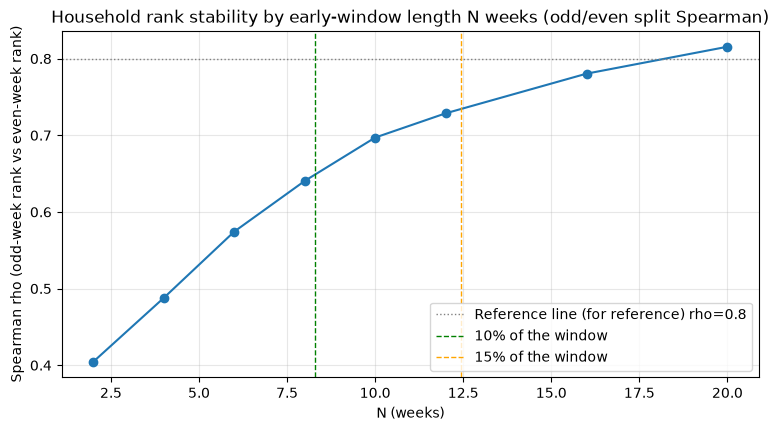

,N,n_households,spearman_rho,pct_of_stable_range
0,2,947,0.404566,2.4
1,4,1397,0.487859,4.8
2,6,1663,0.574319,7.2
3,8,1812,0.640430,9.6
4,10,1913,0.697030,12.0
5,12,1986,0.728662,14.5
6,16,2110,0.780408,19.3
7,20,2188,0.815526,24.1


In [12]:
# Plot the rank-stability curve
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rank_stability["N"], rank_stability["spearman_rho"], marker='o')
ax.axhline(0.8, color='gray', linestyle=':', linewidth=1, label='Reference line (for reference) rho=0.8')

# Mark the 10-15% upper limit of the stable window
ax.axvline(total_stable_weeks * 0.10, color='green', linestyle='--', linewidth=1, label='10% of the window')
ax.axvline(total_stable_weeks * 0.15, color='orange', linestyle='--', linewidth=1, label='15% of the window')

ax.set_title("Household rank stability by early-window length N weeks (odd/even split Spearman)")
ax.set_xlabel("N (weeks)")
ax.set_ylabel("Spearman rho (odd-week rank vs even-week rank)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

rank_stability

In [13]:
from importlib.metadata import version
print("kneed", version("kneed"))  # required: pip install kneed

kneed 0.8.6


In [14]:
# Automatic elbow detection (use kneed if available, otherwise a manual approximation based on the increments)
valid = rank_stability.dropna(subset=["spearman_rho"])

try:
    from kneed import KneeLocator
    kl = KneeLocator(valid["N"], valid["spearman_rho"], curve="concave", direction="increasing")
    print(f"Elbow from kneed: N = {kl.knee} weeks")
except ImportError:
    # Manual: the point where the increase in rho flattens out most sharply as N grows
    diffs = valid["spearman_rho"].diff()
    diff_change = diffs.diff()  # change in the increments (second difference)
    elbow_idx = diff_change.idxmin()  # the point where the increments bend most sharply
    print(f"(kneed not installed, manual approximation) elbow candidate: N = {valid.loc[elbow_idx, 'N']} weeks")
    print("For exact automatic detection: pip install kneed --break-system-packages")

print("\n10-15% upper limit of the whole stable window:", round(total_stable_weeks*0.10,1), "to", round(total_stable_weeks*0.15,1), "weeks")

Elbow from kneed: N = 10 weeks

10-15% upper limit of the whole stable window: 8.3 to 12.4 weeks


In [15]:
# Summary table to help settle the final N
rank_stability["within_10_15pct_rule"] = rank_stability["N"] <= total_stable_weeks * 0.15
rank_stability

,N,n_households,spearman_rho,pct_of_stable_range,within_10_15pct_rule
0,2,947,0.404566,2.4,True
1,4,1397,0.487859,4.8,True
2,6,1663,0.574319,7.2,True
3,8,1812,0.640430,9.6,True
4,10,1913,0.697030,12.0,True
5,12,1986,0.728662,14.5,True
6,16,2110,0.780408,19.3,False
7,20,2188,0.815526,24.1,False


In [16]:
# --- source CSV: rank stability by early-window length N, and the elbow
rank_stability.to_csv(
    OUT_DIR / "h4_rank_stability.csv", index=False)
pd.DataFrame([{
    "stable_min_week": stable_min_week, "stable_max_week": stable_max_week,
    "total_stable_weeks": total_stable_weeks, "kneed_elbow_n": kl.knee,
    "rule_10pct_weeks": total_stable_weeks * 0.10, "rule_15pct_weeks": total_stable_weeks * 0.15,
    "chosen_early_n": 10,
}]).to_csv(OUT_DIR / "h4_early_window_choice.csv", index=False)

Pareto curve (deciding the top X%)

In [17]:
# Spending per household for N = 10 weeks (early window)
early_window = tx_stable[
    (tx_stable["WEEK_NO"] >= stable_min_week) &
    (tx_stable["WEEK_NO"] < stable_min_week + 10)
].copy()

hh_early_sales = early_window.groupby("household_key")["SALES_VALUE"].sum().sort_values(ascending=False, kind="stable")

print(f"Households on the early 10-week basis: {len(hh_early_sales):,}")
print(hh_early_sales.describe())

Households on the early 10-week basis: 2,272
count    2272.000000
mean      356.284177
std       393.754770
min         0.790000
25%        91.047500
50%       227.540000
75%       479.062500
max      3700.550000
Name: SALES_VALUE, dtype: float64


In [18]:
# Compute the Pareto (Lorenz) curve
sorted_sales = hh_early_sales.sort_values(ascending=False, kind="stable").values
n = len(sorted_sales)

cum_pct_households = np.arange(1, n + 1) / n * 100
cum_pct_sales = np.cumsum(sorted_sales) / sorted_sales.sum() * 100

lorenz_df = pd.DataFrame({
    "cum_pct_households": cum_pct_households,
    "cum_pct_sales": cum_pct_sales,
})

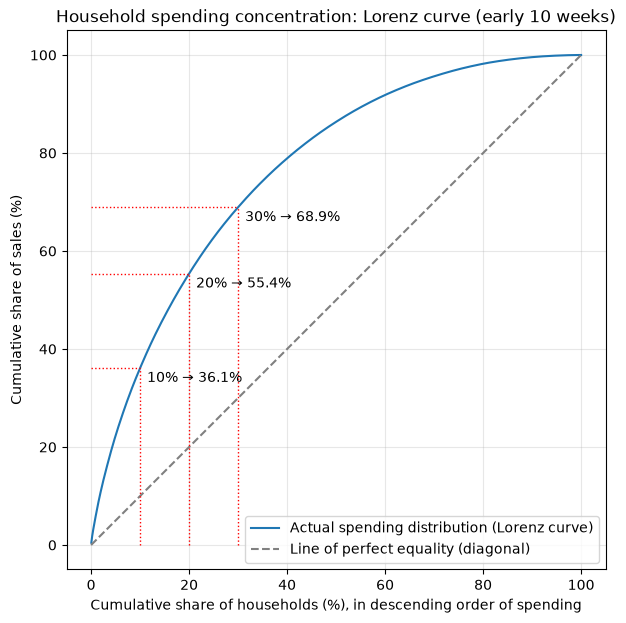

In [19]:
# Plot the Lorenz curve
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(cum_pct_households, cum_pct_sales, label="Actual spending distribution (Lorenz curve)")
ax.plot([0, 100], [0, 100], linestyle='--', color='gray', label="Line of perfect equality (diagonal)")

for x_ref in [10, 20, 30]:
    y_ref = np.interp(x_ref, cum_pct_households, cum_pct_sales)
    ax.plot([x_ref, x_ref], [0, y_ref], color='red', linestyle=':', linewidth=1)
    ax.plot([0, x_ref], [y_ref, y_ref], color='red', linestyle=':', linewidth=1)
    ax.annotate(f"{x_ref}% → {y_ref:.1f}%", (x_ref, y_ref), textcoords="offset points", xytext=(5, -10))

ax.set_title("Household spending concentration: Lorenz curve (early 10 weeks)")
ax.set_xlabel("Cumulative share of households (%), in descending order of spending")
ax.set_ylabel("Cumulative share of sales (%)")
ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect('equal')
plt.show()

In [20]:
# Compute the Gini coefficient (numpy-version compatible)
trapezoid_fn = getattr(np, "trapezoid", None) or np.trapz

gini = 1 - 2 * trapezoid_fn(cum_pct_sales / 100, cum_pct_households / 100)
print(f"Gini coefficient: {gini:.3f} (0 = perfect equality, 1 = perfect concentration)")

Gini coefficient: -0.532 (0 = perfect equality, 1 = perfect concentration)


In [21]:
# --- source CSV: Lorenz curve and Gini (early window, households with sales in weeks 17-26)
lorenz_df.to_csv(OUT_DIR / "h4_lorenz_curve.csv", index=False)
pd.DataFrame([{
    "n_households_early_window": n, "early_sales_total": sorted_sales.sum(),
    "gini_notebook_signed": gini, "gini": abs(gini),
}]).to_csv(OUT_DIR / "h4_gini.csv", index=False)

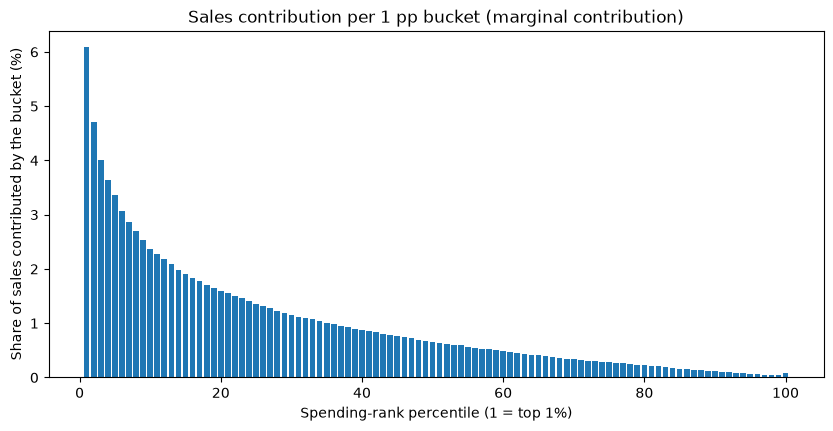

,percentile,bucket_sales,bucket_pct_of_total
0,1,49223.68,6.080919
1,2,38169.39,4.715311
2,3,32470.61,4.011304
3,4,29511.33,3.645725
4,5,27244.65,3.365708
5,6,24820.58,3.066246
6,7,23237.85,2.870722
7,8,21779.78,2.690597
8,9,20565.20,2.540552
9,10,19231.34,2.375772


In [22]:
# Compute the marginal contribution: each 1 percentage point (pp) bucket's contribution to sales
bucket_size_households = max(1, n // 100)  # split households into 100 buckets (1% each)

marginal = []
for i in range(100):
    start = i * bucket_size_households
    end = (i + 1) * bucket_size_households if i < 99 else n
    bucket_sales = sorted_sales[start:end].sum()
    marginal.append({
        "percentile": i + 1,
        "bucket_sales": bucket_sales,
        "bucket_pct_of_total": bucket_sales / sorted_sales.sum() * 100,
    })

marginal_df = pd.DataFrame(marginal)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(marginal_df["percentile"], marginal_df["bucket_pct_of_total"])
ax.set_title("Sales contribution per 1 pp bucket (marginal contribution)")
ax.set_xlabel("Spending-rank percentile (1 = top 1%)")
ax.set_ylabel("Share of sales contributed by the bucket (%)")
plt.show()

marginal_df.head(30)

In [23]:
# Automatic elbow detection (the point where the marginal contribution flattens)
try:
    from kneed import KneeLocator
    kl = KneeLocator(marginal_df["percentile"], marginal_df["bucket_pct_of_total"],
                      curve="convex", direction="decreasing")
    print(f"Elbow from kneed: top {kl.knee}%")
except ImportError:
    pct_change = -marginal_df["bucket_pct_of_total"].diff() / marginal_df["bucket_pct_of_total"].shift(1) * 100
    print("(kneed not installed) rate of decrease in contribution per bucket:")
    print(pct_change.head(30))

Elbow from kneed: top 18%


In [24]:
# Sensitivity table for candidate X values: the conventional 20% versus data-based candidates
candidate_X = [5, 10, 15, 20, 25, 30]
rows = []
for x in candidate_X:
    y = np.interp(x, cum_pct_households, cum_pct_sales)
    rows.append({
        "top_X_pct": x,
        "share_of_sales_pct": round(y, 1),
        "concentration_ratio": round(y / x, 2),
    })

sensitivity_table = pd.DataFrame(rows)
sensitivity_table

,top_X_pct,share_of_sales_pct,concentration_ratio
0,5,22.3,4.47
1,10,36.1,3.61
2,15,46.7,3.11
3,20,55.4,2.77
4,25,62.7,2.51
5,30,68.9,2.30


In [25]:
# --- source CSV: concentration shares (interpolated on the Lorenz curve) and marginal contribution
_x = [1, 5, 10, 15, 20, 25, 30]
_shares = pd.DataFrame({"top_pct_households": _x})
_shares["cum_share_pct"] = np.interp(_x, cum_pct_households, cum_pct_sales)
_shares["concentration_ratio"] = _shares["cum_share_pct"] / _shares["top_pct_households"]
_shares.to_csv(OUT_DIR / "h4_concentration_shares.csv", index=False)
_marg = marginal_df.copy()
_marg["n_households"] = [bucket_size_households] * 99 + [n - 99 * bucket_size_households]
_marg.to_csv(OUT_DIR / "h4_marginal_contribution.csv", index=False)
pd.DataFrame([{"kneed_elbow_top_pct": kl.knee}]).to_csv(OUT_DIR / "h4_marginal_elbow.csv", index=False)